# Figure 6C: test-session block-score overview

In [1]:
import re

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, MultipleLocator
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display

from manuscript_analysis.figures.export import save_label_variants
from manuscript_analysis.figures.fig_utils import APP_COLOUR, CONTROL_COLOUR, ROOT, get_out_path, report_saved
from manuscript_analysis.figures.style import apply_paper_style

apply_paper_style()

PAPER_ARTIFACT_DIR = (
    ROOT / 'results' / 'old_code' / 'saved_data' / 'LSTM_CTRL-CO-DAY150-AD-CO-DAY150_conSpks500_exclu_limBlk'
)
OUTPUT_DIR = get_out_path('6C')
FIGURE_STEM = '6C_test_sessions_overview'
CSV_PATH = OUTPUT_DIR / f'{FIGURE_STEM}.csv'
BLOCK_THRESHOLD = 0.84
EXPECTED_TEST_SESSIONS = {
    f'{name}_NOV24.dat' for name in (
        'EXP11_CTRL-CO-DAY150-6', 'EXP3_CTRL-CO-DAY150-3', 'EXP81_CTRL-CO-DAY150-15', 'EXP12_CTRL-CO-DAY150-7',
        'EXP99_AD-CO-DAY150-23', 'EXP71_AD-CO-DAY150-13', 'EXP78_AD-CO-DAY150-19', 'EXP13_AD-CO-DAY150-5',
        'EXP20_AD-CO-DAY150-6', 'EXP8_AD-CO-DAY150-3', 'EXP6_AD-CO-DAY150-1',
    )
}

In [2]:
model = tf.keras.models.load_model(PAPER_ARTIFACT_DIR / 'Model_CTRL-CO-DAY150-AD-CO-DAY150.keras')
all_blocks, all_labels, all_sessions, all_splits = (
    np.load(PAPER_ARTIFACT_DIR / f'{name}.npy')
    for name in ('X_all', 'session_labels', 'session_ids', 'split_labels')
)
if not len(all_blocks) == len(all_labels) == len(all_sessions) == len(all_splits):
    raise ValueError('The saved paper-era arrays do not have a common block count.')

test_mask = np.char.lower(all_splits.astype(str)) == 'test'
blocks = pd.DataFrame({
    'session': all_sessions[test_mask].astype(str),
    'class_label': all_labels[test_mask].astype(int),
    'score': model.predict(all_blocks[test_mask], verbose=0).reshape(-1),
})
blocks['block_number'] = blocks.groupby('session', sort=False).cumcount().add(1)

observed = set(blocks['session'])
if observed != EXPECTED_TEST_SESSIONS:
    raise ValueError(
        'The saved test partition is not the paper seed-42 split. '
        f'Missing: {sorted(EXPECTED_TEST_SESSIONS - observed)}; '
        f'Unexpected: {sorted(observed - EXPECTED_TEST_SESSIONS)}'
    )

In [3]:
def confidence_weighted_prediction(values, c=4, center=0.5):
    values = np.asarray(values, dtype=float)
    return np.average(values, weights=np.exp(c * np.abs(values - center)))


session_order = (
    blocks.groupby(['session', 'class_label'], sort=False)['score']
    .agg(session_weighted_prediction=confidence_weighted_prediction)
    .reset_index()
)
session_numbers = (
    session_order['session'].str.extract(r'DAY150-(\d+)', flags=re.IGNORECASE, expand=False)
    .astype(int).astype(str)
)
session_order['display_name'] = np.where(
    session_order['class_label'].eq(1), r'hCO$^{APP}$-' + session_numbers, 'hCO-' + session_numbers
)
is_app = session_order['class_label'].eq(1)
session_order = pd.concat([
    session_order[~is_app].sort_values('session_weighted_prediction', kind='stable'),
    session_order[is_app].sort_values('session_weighted_prediction', ascending=False, kind='stable'),
], ignore_index=True)
session_order['session_plot_order'] = session_order.index

blocks = blocks.merge(
    session_order, on=['session', 'class_label'], how='left', validate='many_to_one'
).sort_values('block_number', kind='stable')
blocks.to_csv(CSV_PATH, index=False)
display(session_order)

,session,class_label,session_weighted_prediction,display_name,session_plot_order
0,EXP11_CTRL-CO-DAY150-6_NOV24.dat,0,0.020091,hCO-6,0
1,EXP3_CTRL-CO-DAY150-3_NOV24.dat,0,0.162373,hCO-3,1
2,EXP81_CTRL-CO-DAY150-15_NOV24.dat,0,0.173029,hCO-15,2
3,EXP12_CTRL-CO-DAY150-7_NOV24.dat,0,0.415694,hCO-7,3
4,EXP99_AD-CO-DAY150-23_NOV24.dat,1,0.982131,hCO$^{APP}$-23,4
5,EXP71_AD-CO-DAY150-13_NOV24.dat,1,0.981747,hCO$^{APP}$-13,5
6,EXP78_AD-CO-DAY150-19_NOV24.dat,1,0.978716,hCO$^{APP}$-19,6
7,EXP13_AD-CO-DAY150-5_NOV24.dat,1,0.908738,hCO$^{APP}$-5,7
8,EXP20_AD-CO-DAY150-6_NOV24.dat,1,0.741368,hCO$^{APP}$-6,8
9,EXP8_AD-CO-DAY150-3_NOV24.dat,1,0.708778,hCO$^{APP}$-3,9


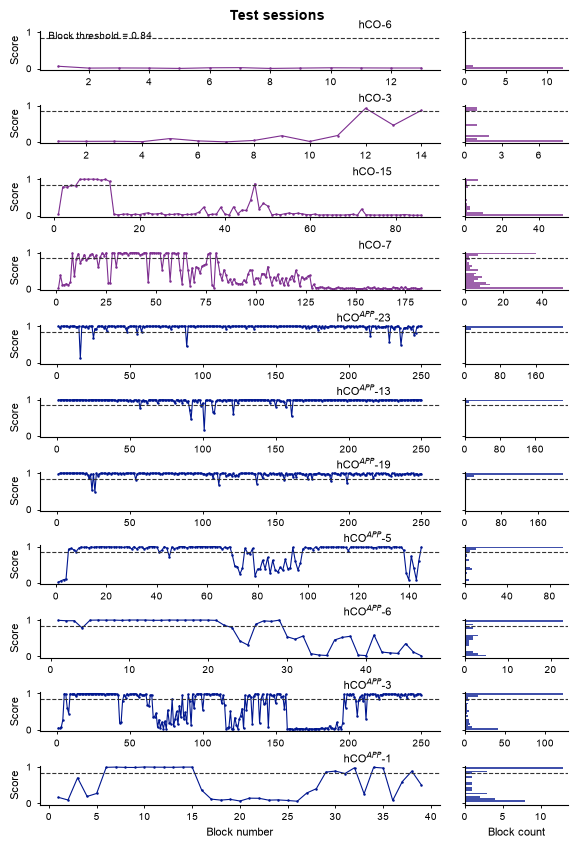

Saved output\figures\6C\6C_test_sessions_overview_with_labels.png
Saved output\figures\6C\6C_test_sessions_overview_with_labels.svg
Saved output\figures\6C\6C_test_sessions_overview_with_labels.pdf
Saved output\figures\6C\6C_test_sessions_overview_without_labels.png
Saved output\figures\6C\6C_test_sessions_overview_without_labels.svg
Saved output\figures\6C\6C_test_sessions_overview_without_labels.pdf
Saved output\figures\6C\6C_test_sessions_overview.csv


In [4]:
def block_tick_interval(block_count):
    cadence = ((15, 2), (45, 5), (55, 10), (155, 20), (200, 25))
    return next((step for limit, step in cadence if block_count <= limit), 50)


n_sessions = len(session_order)
fig = plt.figure(figsize=(6.0, 8.5))
grid = fig.add_gridspec(nrows=n_sessions, ncols=2, width_ratios=(5.2, 1.35), hspace=0.90, wspace=0.10)

for row, session_meta in session_order.iterrows():
    session_data = blocks.loc[blocks['session_plot_order'].eq(row)]
    colour = APP_COLOUR if session_meta['class_label'] == 1 else CONTROL_COLOUR

    ax = fig.add_subplot(grid[row, 0])
    ax_hist = fig.add_subplot(grid[row, 1], sharey=ax)
    ax.plot(
        session_data['block_number'].to_numpy(), session_data['score'].to_numpy(),
        color=colour, linewidth=0.8, marker='o', markersize=1.8, markeredgewidth=0,
    )
    ax_hist.hist(
        session_data['score'].to_numpy(), bins=np.linspace(0, 1, 21), orientation='horizontal',
        color=colour, alpha=0.75, edgecolor='none',
    )
    for plot_axis in (ax, ax_hist):
        plot_axis.axhline(BLOCK_THRESHOLD, color='#333333', linestyle='--', linewidth=0.8)
        plot_axis.spines[['top', 'right']].set_visible(False)

    ax.set_ylim(-0.03, 1.03)
    ax.set_ylabel('Score', fontsize=8)
    ax.set_title(session_meta['display_name'], loc='right', x=0.88, ha='right', fontsize=8, pad=2)
    ax.tick_params(direction='out', length=2.5, width=0.65, labelsize=7)
    ax_hist.tick_params(direction='out', length=2.5, width=0.65, labelsize=7, labelleft=False)
    ax.xaxis.set_major_locator(MultipleLocator(block_tick_interval(len(session_data))))
    ax_hist.xaxis.set_major_locator(MaxNLocator(nbins=3, integer=True))

    if row == 0:
        ax.text(0.02, 0.80, f'Block threshold = {BLOCK_THRESHOLD:.2f}', transform=ax.transAxes, fontsize=7)
    if row == n_sessions - 1:
        ax.set_xlabel('Block number', fontsize=8)
        ax_hist.set_xlabel('Block count', fontsize=8)

fig.suptitle('Test sessions', fontsize=10, fontweight='bold', y=0.990)
fig.subplots_adjust(left=0.105, right=0.985, bottom=0.055, top=0.965)
saved_paths = save_label_variants(fig, OUTPUT_DIR, FIGURE_STEM, dpi=300)
plt.show()
report_saved([*saved_paths, CSV_PATH])